In [53]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
from torch import nn
from torch.utils.data import DataLoader
from torchlake.common.constants import IMAGENET_MEAN, IMAGENET_STD
from torchlake.common.controller.trainer import ClassificationTrainer
from torchlake.common.controller.evaluator import ClassificationEvaluator
from torchlake.common.utils.convert import img_tensor_to_np
from torchlake.common.utils.platform import get_file_size, get_num_workers
from torchlake.image_classification.models.vovnet import VoVNet
from torchvision import transforms
from torchvision.datasets import EuroSAT
from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Setting

In [54]:
SEED = 42

In [55]:
IMAGE_SIZE = 224
BATCH_SIZE = 16

In [56]:
artifact_path = Path("../../artifacts/vovnet")
artifact_path.mkdir(exist_ok=True)

data_path = Path("../../data/euroSAT")

In [57]:
DEVICE = torch.device("cuda:0")

# data

In [58]:
preprocess = transforms.Compose(
    [
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [59]:
test_preprocess = transforms.Compose(
    [
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]
)

In [81]:
train_dataset = EuroSAT(
    data_path.as_posix(),
    transform=preprocess,
    download=True,
)

In [82]:
NUM_CLASS = len(train_dataset.classes)

In [83]:
CLASS_NAMES = train_dataset.classes
CLASS_NAMES

['AnnualCrop',
 'Forest',
 'HerbaceousVegetation',
 'Highway',
 'Industrial',
 'Pasture',
 'PermanentCrop',
 'Residential',
 'River',
 'SeaLake']

In [84]:
len(train_dataset)

27000

Pasture


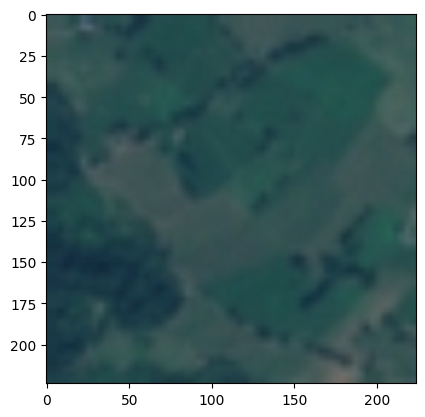

In [64]:
import random

demo_img, demo_label = train_dataset[random.randint(0, len(train_dataset))]
print(train_dataset.classes[demo_label])
plt.imshow((img_tensor_to_np(demo_img) * IMAGENET_STD + IMAGENET_MEAN).clip(0, 1))

In [65]:
test_dataset = EuroSAT(
    data_path.as_posix(),
    transform=test_preprocess,
)

In [85]:
train_idx, test_idx = train_test_split(
    range(len(train_dataset)),
    test_size=0.2,
    stratify=train_dataset.targets,
    random_state=SEED,
)

In [86]:
train_dataset = Subset(train_dataset, train_idx)
test_dataset = Subset(test_dataset, test_idx)

In [87]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    pin_memory=True,
    num_workers=get_num_workers(),
)

# model

In [69]:
model = VoVNet(output_size=NUM_CLASS, key="27_slim").to(DEVICE)

In [70]:
torchinfo.summary(model)

Layer (type:depth-idx)                                       Param #
VoVNet                                                       --
├─Sequential: 1-1                                            --
│    └─Conv2dNormActivation: 2-1                             --
│    │    └─Conv2d: 3-1                                      1,728
│    │    └─BatchNorm2d: 3-2                                 128
│    │    └─ReLU: 3-3                                        --
│    └─Conv2dNormActivation: 2-2                             --
│    │    └─Conv2d: 3-4                                      36,864
│    │    └─BatchNorm2d: 3-5                                 128
│    │    └─ReLU: 3-6                                        --
│    └─Conv2dNormActivation: 2-3                             --
│    │    └─Conv2d: 3-7                                      73,728
│    │    └─BatchNorm2d: 3-8                                 256
│    │    └─ReLU: 3-9                                        --
├─Sequential: 1-2    

# training

In [71]:
EPOCH = 10
acc_iters = 64 // BATCH_SIZE

In [72]:
criterion = nn.CrossEntropyLoss()
optim = torch.optim.Adam(model.parameters(), lr=1e-3)

In [73]:
trainer = ClassificationTrainer(EPOCH, DEVICE, acc_iters=acc_iters)
trainer.recorder.increment_dataset_size(len(train_dataset))

In [74]:
training_loss = trainer.run(train_loader, model, optim, criterion)

Enable AMP: False
Training...


100%|██████████| 1350/1350 [07:58<00:00,  2.82it/s]


------------------------------------
Epoch 1
------------------------------------
total: 1.5553e-02 (0.00%)


100%|██████████| 1350/1350 [01:26<00:00, 15.57it/s]


------------------------------------
Epoch 2
------------------------------------
total: 9.3101e-03 (-40.00%)


100%|██████████| 1350/1350 [01:25<00:00, 15.73it/s]


... (11 outputs left out)

100%|██████████| 1350/1350 [01:26<00:00, 15.62it/s]


------------------------------------
Epoch 9
------------------------------------
total: 3.0701e-03 (-6.00%)


100%|██████████| 1350/1350 [01:25<00:00, 15.73it/s]

------------------------------------
Epoch 10
------------------------------------
total: 2.8617e-03 (-7.00%)


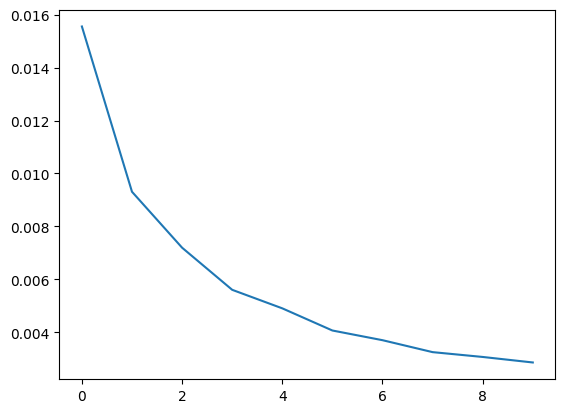

In [75]:
plt.plot(training_loss)

# inference

In [76]:
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    pin_memory=True,
    num_workers=get_num_workers(),
)

In [77]:
evaluator = ClassificationEvaluator(NUM_CLASS, DEVICE)

In [91]:
confusion_matrix = evaluator.run(test_loader, model)

100%|██████████| 338/338 [00:13<00:00, 24.68it/s]


In [92]:
per_class_acc = evaluator.get_per_class_accuracy(confusion_matrix)
evaluator.show_per_class_accuracy(CLASS_NAMES, per_class_acc)

AnnualCrop: 0.91
Forest    : 0.9816666666666667
HerbaceousVegetation: 0.88
Highway   : 0.958
Industrial: 0.93
Pasture   : 0.9475
PermanentCrop: 0.95
Residential: 0.9966666666666667
River     : 0.95
SeaLake   : 0.99


In [93]:
per_class_acc.mean()

np.float64(0.9493833333333332)

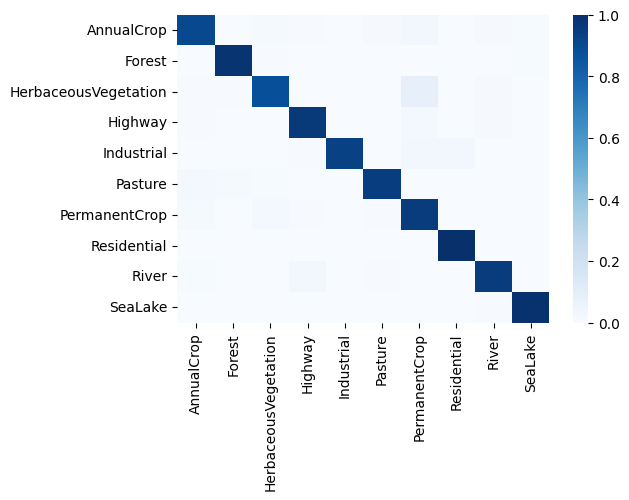

In [94]:
evaluator.plot_confusion_matrix(
    confusion_matrix,
    CLASS_NAMES,
    "Blues",
    annot=False,
    figsize=(6, 4),
)

# file

In [99]:
model_path = artifact_path / f"vovnet.{model.key}.pth"
model_path

WindowsPath('../../artifacts/vovnet/vovnet.27_slim.pth')

In [96]:
torch.save(model.state_dict(), model_path)

In [97]:
get_file_size(model_path)

'11.59MiB'

In [98]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>